In [1]:

!pip -q install -U "transformers>=4.51.0" pymupdf accelerate sentencepiece

import os
import re
import json
import torch
import fitz

from pathlib import Path
from google.colab import files
from transformers import AutoTokenizer

project_dir = Path("/content/bhutan_imf")
project_dir.mkdir(exist_ok=True)

model_name = "Qwen/Qwen3-14B"

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")
print("Project folder:", project_dir)

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


GPU: NVIDIA A100-SXM4-80GB
Project folder: /content/bhutan_imf


Upload PDF

In [2]:

uploaded = files.upload()
pdf_path = next((Path(name) for name in uploaded if name.lower().endswith(".pdf")), None)

if pdf_path is None:
    raise ValueError("Please upload the Bhutan IMF PDF.")

def clean_text(text):
    text = text.replace("\u00a0", " ")
    text = re.sub(r"(?<=\w)-\n(?=\w)", "", text)
    lines = []

    for line in text.splitlines():
        line = re.sub(r"[ \t]+", " ", line).strip()

        if not line:
            continue
        if "©International Monetary Fund. Not for Redistribution" in line:
            continue
        if re.fullmatch(r"(?:BHUTAN|INTERNATIONAL MONETARY FUND|\d+)", line, re.I):
            continue

        lines.append(line)

    return "\n".join(lines)

doc = fitz.open(pdf_path)

pages = [
    {
        "page": i + 1,
        "text": clean_text(page.get_text("text", sort=True))
    }
    for i, page in enumerate(doc)
]

doc.close()

full_text = "\n\n".join(p["text"] for p in pages)

with open(project_dir / "bhutan_pages.json", "w") as f:
    json.dump(pages, f, indent=2, ensure_ascii=False)

(project_dir / "bhutan_cleaned_text.txt").write_text(
    full_text, encoding="utf-8"
)

print("PDF pages:", len(pages))
print("Extracted characters:", len(full_text))
print("Pages containing text:", sum(bool(p["text"]) for p in pages))
print("\nText preview:\n", full_text[:600])

Saving 1934-7685-002.2026.issue-019-en (1).pdf to 1934-7685-002.2026.issue-019-en (1).pdf
PDF pages: 84
Extracted characters: 221525
Pages containing text: 83

Text preview:
 

IMF Country Report No. 26/19
2025 ARTICLE IV CONSULTATION—PRESS RELEASE;
January 2026 AND STAFF REPORT
Under Article IV of the IMF’s Articles of Agreement, the IMF holds bilateral discussions
with members, usually every year. In the context of the Article IV consultation with
Bhutan, the following documents have been released and are included in this package:
• A Press Release
• The Staff Report prepared by a staff team of the IMF for the Executive Board’s
consideration on lapse-of-time, following discussions that ended on
November 4, 2025, with the officials of Bhutan on economic developmen


Section-aware token chunking

In [3]:
tokenizer = AutoTokenizer.from_pretrained(model_name)

section_names = [
    "CONTEXT",
    "RECENT DEVELOPMENTS, OUTLOOK AND RISKS",
    "A. Recent Developments",
    "B. Outlook and Risks",
    "POLICY DISCUSSIONS",
    "A. Fiscal Policy",
    "B. Monetary, External and Financial Sector Policies",
    "C. The Gelephu Mindfulness City Project",
    "D. Structural Issues",
    "STAFF APPRAISAL"
]

def identify_section(line):
    normalized = re.sub(r"[\s_]+", " ", line).strip().rstrip(".")
    for section in section_names:
        if normalized.casefold() == section.casefold():
            return section
    return None

def make_chunks(pages, tokenizer, chunk_size=450, overlap=50):
    chunks = []
    current_section = "Front matter"

    for page in pages:
        segments = []
        buffer = []

        for line in page["text"].splitlines():
            # Main report begins on PDF page 11.
            heading = identify_section(line) if page["page"] >= 11 else None

            if heading:
                if buffer:
                    segments.append((current_section, "\n".join(buffer)))
                    buffer = []
                current_section = heading

            buffer.append(line)

        if buffer:
            segments.append((current_section, "\n".join(buffer)))

        for section, segment_text in segments:
            tokens = tokenizer.encode(segment_text, add_special_tokens=False)

            for start in range(0, len(tokens), chunk_size - overlap):
                part = tokens[start:start + chunk_size]

                if not part:
                    continue

                chunks.append({
                    "chunk_id": len(chunks),
                    "page": page["page"],
                    "section": section,
                    "token_count": len(part),
                    "text": tokenizer.decode(part, skip_special_tokens=True)
                })

                if start + chunk_size >= len(tokens):
                    break

    return chunks

chunks = make_chunks(pages, tokenizer)

with open(project_dir / "bhutan_chunks.json", "w") as f:
    json.dump(chunks, f, indent=2, ensure_ascii=False)

token_counts = [c["token_count"] for c in chunks]

print("Total chunks:", len(chunks))
print("Average tokens:", round(sum(token_counts) / len(token_counts), 1))
print("Maximum tokens:", max(token_counts))
print("Pages covered:", len(set(c["page"] for c in chunks)))
print("Sections detected:", len(set(c["section"] for c in chunks)))

print("\nFirst chunk:")
print(chunks[0]["text"][:500])

config.json:   0%|          | 0.00/728 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

Total chunks: 216
Average tokens: 356.4
Maximum tokens: 450
Pages covered: 83
Sections detected: 11

First chunk:
IMF Country Report No. 26/19
2025 ARTICLE IV CONSULTATION—PRESS RELEASE;
January 2026 AND STAFF REPORT
Under Article IV of the IMF’s Articles of Agreement, the IMF holds bilateral discussions
with members, usually every year. In the context of the Article IV consultation with
Bhutan, the following documents have been released and are included in this package:
• A Press Release
• The Staff Report prepared by a staff team of the IMF for the Executive Board’s
consideration on lapse-of-time, followi


Load Qwen3-14B

In [4]:
!pip -q install -U bitsandbytes

import torch
from transformers import AutoModelForCausalLM, BitsAndBytesConfig

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16
)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=quant_config,
    device_map="auto",
    torch_dtype=torch.bfloat16
)

model.eval()

print("Qwen3-14B loaded successfully!")
print("GPU:", torch.cuda.get_device_name(0))

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/36.5k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/443 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Qwen3-14B loaded successfully!
GPU: NVIDIA A100-SXM4-80GB


Test financial summarisation

In [5]:

def ask_llm(prompt, max_new_tokens=220):
    messages = [
        {
            "role": "system",
            "content": (
                "You are an economic research assistant analysing an IMF report. "
                "Use only the supplied source text. Do not invent figures or claims. "
                "Write in clear academic English."
            )
        },
        {"role": "user", "content": prompt}
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    inputs = tokenizer(text, return_tensors="pt").to(model.device)

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    answer = tokenizer.decode(
        output[0][inputs["input_ids"].shape[-1]:],
        skip_special_tokens=True
    )

    return answer.strip()

sample = next(
    c for c in chunks
    if "hydropower" in c["text"].lower()
    and c["page"] >= 11
)

prompt = f"""
Summarise the following IMF Bhutan report passage in fewer than 100 words.

Focus on economic growth, financial stability, and risks.

Source text:
{sample['text']}
"""

print(ask_llm(prompt))

Bhutan's economic growth slowed in 2023 due to import restrictions, declining foreign reserves, fiscal consolidation, and a tourism tax hike, though it is projected to recover in 2024 with hydropower projects and increased capital spending. Food inflation posed additional challenges. Medium-term risks include over-reliance on hydropower and low-productivity sectors, necessitating economic diversification and youth employment opportunities. The GMC project may aid growth but carries fiscal risks. Strengthening the financial sector is crucial to support emerging industries.


Generate and save section summaries

In [6]:
from collections import defaultdict

sections_to_summarise = [
    "CONTEXT",
    "A. Recent Developments",
    "B. Outlook and Risks",
    "A. Fiscal Policy",
    "B. Monetary, External and Financial Sector Policies",
    "C. The Gelephu Mindfulness City Project",
    "D. Structural Issues",
    "STAFF APPRAISAL"
]

section_chunks = defaultdict(list)

# Main staff report only; exclude later tables and annexes.
for chunk in chunks:
    if 11 <= chunk["page"] <= 24:
        if chunk["section"] in sections_to_summarise:
            section_chunks[chunk["section"]].append(chunk)

section_summaries = {}

def summarise_section(name, items):
    partials = []

    for i in range(0, len(items), 6):
        batch = items[i:i + 6]
        source = "\n".join(c["text"] for c in batch)

        prompt = f"""
Summarise this section of Bhutan's IMF report in 80-100 words.

Section: {name}

Use only the supplied text. Preserve important economic
figures, policy recommendations and risks. Do not invent facts.

Source:
{source}
"""
        partials.append(ask_llm(prompt, max_new_tokens=200))

    combined = "\n".join(partials)

    final_prompt = f"""
Write one final summary of the IMF section "{name}".

Requirements:
- Maximum 90 words.
- Clear academic English.
- Focus on key economic findings and policy implications.
- Use only the evidence below.
- Do not include introductory phrases.

Evidence:
{combined}
"""
    return ask_llm(final_prompt, max_new_tokens=160)

for name in sections_to_summarise:
    items = section_chunks.get(name, [])

    if not items:
        print("Section not found:", name)
        continue

    summary = summarise_section(name, items)

    section_summaries[name] = {
        "summary": summary,
        "word_count": len(summary.split()),
        "source_pages": sorted(set(c["page"] for c in items))
    }

    print(f"{name}: {len(summary.split())} words")

with open(project_dir / "bhutan_section_summaries.json", "w") as f:
    json.dump(section_summaries, f, indent=2, ensure_ascii=False)

print("\nSaved section summaries:", len(section_summaries))

CONTEXT: 68 words
A. Recent Developments: 98 words
B. Outlook and Risks: 75 words
A. Fiscal Policy: 82 words
B. Monetary, External and Financial Sector Policies: 79 words
C. The Gelephu Mindfulness City Project: 91 words
D. Structural Issues: 66 words
STAFF APPRAISAL: 68 words

Saved section summaries: 8


Generate executive summary

In [7]:
summary_text = "\n\n".join(
    f"{name}: {data['summary']}"
    for name, data in section_summaries.items()
)

executive_prompt = f"""
Create an executive summary of Bhutan's IMF 2025 Article IV report.

Write 5-6 concise bullet points covering:
- Economic growth and inflation
- Fiscal policy and public debt
- Financial sector stability
- External sector and reserves
- Major vulnerabilities
- IMF policy recommendations

Use only the section summaries below.
Preserve important numerical values.
Avoid unsupported conclusions.

Section summaries:
{summary_text}
"""

executive_summary = ask_llm(executive_prompt, max_new_tokens=450)

with open(project_dir / "bhutan_executive_summary.json", "w") as f:
    json.dump({
        "country": "Bhutan",
        "report": "IMF Country Report 26/019",
        "executive_summary": executive_summary
    }, f, indent=2, ensure_ascii=False)

print(executive_summary)

- **Economic growth and inflation**: Bhutan experienced strong GDP growth of 9.1% in Q4 2024, driven by industry and services, though inflation rose to 3.5% in FY2025/26 due to food price increases, up from below 2% mid-2024.

- **Fiscal policy and public debt**: The fiscal deficit widened to 2.6% of GDP, with a target of 3% over the 13th FYP. Public debt is expected to decline due to non-recourse hydropower financing, but fiscal discipline and improved budgeting are essential for sustainability.

- **Financial sector stability**: The financial sector faces risks from high credit growth, low deposit rates, and sectoral concentration. Strengthening prudential regulations, increasing reserve requirements, and addressing non-performing loans are recommended to enhance stability.

- **External sector and reserves**: The current account deficit improved to 19% of GDP, supported by remittances and tourism, but reserves remain below the ARA metric. A negative net international investment posi

six financial indicators

In [8]:

import json
import re

indicators = {
    "gdp_growth_forecast_pct": [
        "real GDP growth", "GDP growth", "growth projected"
    ],
    "headline_inflation_rate_pct": [
        "headline inflation", "consumer prices", "inflation forecast"
    ],
    "central_bank_policy_rate_pct": [
        "policy rate", "interest rate corridor", "monetary policy rate"
    ],
    "non_performing_loan_ratio": [
        "non-performing loans", "NPLs", "nonperforming loans"
    ],
    "unemployment_rate_pct": [
        "unemployment rate", "overall unemployment"
    ],
    "tier_1_capital_ratio": [
        "tier 1 capital", "tier-1", "tier 1 ratio"
    ]
}

def retrieve_evidence(terms, top_k=5):
    ranked = []

    for chunk in chunks:
        source = chunk["text"].lower()
        score = sum(source.count(term.lower()) for term in terms)

        if score > 0:
            ranked.append((score, chunk))

    ranked.sort(key=lambda item: item[0], reverse=True)

    selected = ranked[:top_k]
    return "\n\n".join(
        f"[PDF page {item['page']}]\n{item['text']}"
        for _, item in selected
    )

def parse_json_answer(answer):
    decoder = json.JSONDecoder()

    for match in re.finditer(r"\{", answer):
        try:
            obj, _ = decoder.raw_decode(answer[match.start():])
            if isinstance(obj, dict):
                return obj
        except json.JSONDecodeError:
            continue

    return {}

financial_data = {"country_name": "Bhutan"}
financial_audit = {}

for indicator, terms in indicators.items():
    evidence = retrieve_evidence(terms)

    prompt = f"""
Extract the indicator "{indicator}" from this IMF Bhutan report.

Rules:
- Return one JSON object only.
- Fields: value, source_page, evidence, status.
- value must be a percentage number or null.
- source_page must be the PDF page number or null.
- status must be "found" or "missing".
- Use the latest relevant observation, except GDP growth and
  inflation, where the FY2025/26 forecast is required.
- For inflation use average headline inflation, not end-period inflation.
- For Tier 1 capital, do not substitute total capital adequacy.
- For the policy rate, do not substitute the cash reserve ratio,
  minimum lending rate, or another monetary instrument.
- If the exact indicator cannot be established, return null.
- Never invent numerical values.

Source passages:
{evidence}
"""

    answer = ask_llm(prompt, max_new_tokens=280)
    result = parse_json_answer(answer)

    value = result.get("value")

    try:
        value = float(value) if value is not None else None
    except (TypeError, ValueError):
        value = None

    page = result.get("source_page")
    candidate_pages = set(
        int(p) for p in re.findall(r"\[PDF page (\d+)\]", evidence)
    )

    try:
        page = int(page)
    except (TypeError, ValueError):
        page = None

    if page not in candidate_pages:
        page = None
        value = None

    financial_data[indicator] = value

    financial_audit[indicator] = {
        "value": value,
        "source_page": page,
        "evidence": str(result.get("evidence", "")),
        "status": "extracted_unverified" if value is not None else "missing"
    }

    print(f"{indicator}: {value} | PDF page: {page}")

with open(project_dir / "bhutan_financial_data.json", "w") as f:
    json.dump(financial_data, f, indent=2)

with open(project_dir / "bhutan_financial_audit.json", "w") as f:
    json.dump(financial_audit, f, indent=2)

print("\nFinancial JSON and extraction audit saved.")

gdp_growth_forecast_pct: 7.4 | PDF page: 14
headline_inflation_rate_pct: 3.5 | PDF page: 14
central_bank_policy_rate_pct: None | PDF page: 19
non_performing_loan_ratio: 8.0 | PDF page: 35
unemployment_rate_pct: 3.2 | PDF page: 12
tier_1_capital_ratio: None | PDF page: None

Financial JSON and extraction audit saved.


Seven financial stability themes

In [9]:

import pandas as pd

themes = {
    "Inflation & Prices": [
        r"\binflation\b", r"\bconsumer prices?\b",
        r"\bprice pressures?\b"
    ],
    "Interest Rates & Credit": [
        r"\binterest rates?\b", r"\bcredit growth\b",
        r"\blending rates?\b"
    ],
    "Housing & Real Estate": [
        r"\bhousing\b", r"\breal estate\b",
        r"\bproperty market\b", r"\bmortgage\b"
    ],
    "Banking Capital & Liquidity": [
        r"\bcapital adequacy\b", r"\bbank liquidity\b",
        r"\bcapital buffers?\b", r"\bexcess liquidity\b"
    ],
    "Sovereign Debt": [
        r"\bpublic debt\b", r"\bdebt sustainability\b",
        r"\bgovernment debt\b", r"\bdebt distress\b"
    ],
    "Labor Market Dynamics": [
        r"\bunemployment\b", r"\bemployment\b",
        r"\blabor market\b", r"\bemigration\b"
    ],
    "Systemic Financial Risk": [
        r"\bfinancial stability\b", r"\bsystemic risk\b",
        r"\bfinancial sector risks?\b",
        r"\bnon.performing loans?\b"
    ]
}

theme_counts = {}

for theme, patterns in themes.items():
    total = 0

    for page in pages:
        for pattern in patterns:
            total += len(re.findall(
                pattern, page["text"], flags=re.IGNORECASE
            ))

    theme_counts[theme] = total

theme_df = pd.DataFrame({
    "theme": list(theme_counts.keys()),
    "count": list(theme_counts.values())
})

total_matches = theme_df["count"].sum()

theme_df["percentage"] = (
    theme_df["count"] / total_matches * 100
).round(2) if total_matches else 0.0

theme_df = theme_df.sort_values(
    "count", ascending=False
).reset_index(drop=True)

theme_df.to_json(
    project_dir / "bhutan_financial_themes.json",
    orient="records",
    indent=2
)

theme_df.to_csv(
    project_dir / "bhutan_financial_themes.csv",
    index=False
)

print(theme_df.to_string(index=False))
print("\nTotal keyword matches:", total_matches)

                      theme  count  percentage
             Sovereign Debt     71       40.11
         Inflation & Prices     34       19.21
      Labor Market Dynamics     29       16.38
    Interest Rates & Credit     25       14.12
Banking Capital & Liquidity      9        5.08
    Systemic Financial Risk      5        2.82
      Housing & Real Estate      4        2.26

Total keyword matches: 177


In [10]:
financial_data["non_performing_loan_ratio"] = 3.2

financial_audit["non_performing_loan_ratio"] = {
    "value": 3.2,
    "source_page": 13,
    "evidence": "NPLs standing at 3.2 percent (8 percent with charge-offs), September 2025.",
    "status": "source_verified"
}

# Preserve genuine missing values.
for name in [
    "central_bank_policy_rate_pct",
    "tier_1_capital_ratio"
]:
    financial_data[name] = None
    financial_audit[name] = {
        "value": None,
        "source_page": None,
        "evidence": "Exact indicator not verified in the report.",
        "status": "missing_unverified"
    }

with open(project_dir / "bhutan_financial_data.json", "w") as f:
    json.dump(financial_data, f, indent=2)

with open(project_dir / "bhutan_financial_audit.json", "w") as f:
    json.dump(financial_audit, f, indent=2)

print(json.dumps(financial_data, indent=2))

{
  "country_name": "Bhutan",
  "gdp_growth_forecast_pct": 7.4,
  "headline_inflation_rate_pct": 3.5,
  "central_bank_policy_rate_pct": null,
  "non_performing_loan_ratio": 3.2,
  "unemployment_rate_pct": 3.2,
  "tier_1_capital_ratio": null
}


qualitative insights

In [11]:

risk_terms = [
    "growth", "hydropower", "tourism", "fiscal",
    "financial stability", "public debt", "GMC",
    "employment", "reserves", "climate"
]

evidence_chunks = []

for chunk in chunks:
    if 11 <= chunk["page"] <= 26:
        score = sum(
            term in chunk["text"].lower()
            for term in risk_terms
        )
        evidence_chunks.append((score, chunk))

evidence_chunks.sort(key=lambda x: x[0], reverse=True)

source = "\n\n".join(
    f"[PDF page {c['page']}]\n{c['text']}"
    for _, c in evidence_chunks[:12]
)

prompt = f"""
Analyse Bhutan's macroeconomic and financial stability position
using the IMF report evidence below.

Return only valid JSON with these fields:
- strengths: exactly 6 short strings
- vulnerabilities: exactly 6 short strings

Rules:
- Use only evidence from the report.
- Focus on growth drivers, economic resilience,
  financial stability and structural challenges.
- Avoid duplicating points.
- Do not invent numerical values.
- Use clear, concise academic English.

Source:
{source}
"""

answer = ask_llm(prompt, max_new_tokens=800)
qualitative_data = parse_json_answer(answer)

# Validate the required structure before saving.
valid = (
    isinstance(qualitative_data.get("strengths"), list)
    and isinstance(qualitative_data.get("vulnerabilities"), list)
    and len(qualitative_data["strengths"]) == 6
    and len(qualitative_data["vulnerabilities"]) == 6
    and all(
        isinstance(item, str) and item.strip()
        for group in ["strengths", "vulnerabilities"]
        for item in qualitative_data[group]
    )
)

if not valid:
    print("Model output requires review:")
    print(answer)
else:
    with open(project_dir / "bhutan_qualitative_insights.json", "w") as f:
        json.dump(qualitative_data, f, indent=2, ensure_ascii=False)

    print("ECONOMIC STRENGTHS")
    for i, item in enumerate(qualitative_data["strengths"], 1):
        print(f"{i}. {item}")

    print("\nVULNERABILITIES")
    for i, item in enumerate(qualitative_data["vulnerabilities"], 1):
        print(f"{i}. {item}")

    print("\nQualitative insights saved.")

ECONOMIC STRENGTHS
1. Bhutan has eliminated extreme poverty and reduced inequality significantly.
2. The country maintains a strong commitment to environmental sustainability and climate neutrality.
3. Growth is supported by major hydropower projects and increased capital spending under the 13th Five Year Plan.
4. Tourism has shown recovery with increased arrivals and higher spending from non-Indian tourists.
5. Foreign reserves have improved, reaching US$1 billion, though still below the ARA metric.
6. The financial sector remains stable with a capital adequacy ratio well above the regulatory requirement.

VULNERABILITIES
1. The economy remains heavily dependent on hydropower and trade with India, limiting diversification.
2. A significant structural current account deficit persists, financed mainly through external loans and grants.
3. Public and publicly guaranteed debt is projected to rise to 141% of GDP, increasing fiscal risks.
4. The country faces exposure to global risks such a

In [13]:
import pandas as pd
import re

# IMF Bhutan report - PDF page 7
table_text = pages[6]["text"]

trend_rows = {
    "Real GDP growth": r"^Real GDP growth \(percent change\).*",
    "Average inflation": r"^Consumer prices \(avg; percent change\).*",
    "Public debt": r"^General government debt 3/.*",
    "Current account balance": r"^Current account balance.*"
}

years = ["2023/24", "2024/25", "2025/26", "2026/27"]
records = []

for indicator, pattern in trend_rows.items():
    match = re.search(pattern, table_text, re.I | re.M)

    if not match:
        raise ValueError(f"Indicator not found: {indicator}")

    row = match.group(0)
    numbers = re.findall(r"(?<![\w/])-?\d+(?:,\d{3})*(?:\.\d+)?(?![\w/])", row)

    values = [float(x.replace(",", "")) for x in numbers[-4:]]

    if len(values) != 4:
        raise ValueError(f"Invalid values for {indicator}: {row}")

    records.append({
        "indicator": indicator,
        **dict(zip(years, values))
    })

trend_wide = pd.DataFrame(records)

trend_long = pd.melt(
    trend_wide,
    id_vars="indicator",
    var_name="year",
    value_name="value"
)

trend_long["unit"] = trend_long["indicator"].map({
    "Real GDP growth": "Percent change",
    "Average inflation": "Percent change",
    "Public debt": "Percent of GDP",
    "Current account balance": "Percent of GDP"
})

trend_long["period_status"] = trend_long["year"].map({
    "2023/24": "Actual",
    "2024/25": "Estimate",
    "2025/26": "Projection",
    "2026/27": "Projection"
})

trend_long["source_page"] = 7

trend_wide.to_csv(project_dir / "bhutan_trends_wide.csv", index=False)
trend_long.to_csv(project_dir / "bhutan_trends_long.csv", index=False)

trend_long.to_json(
    project_dir / "bhutan_economic_trends.json",
    orient="records",
    indent=2
)

print("FOUR ECONOMIC TREND SERIES")
print(trend_wide.to_string(index=False))
print("\nSeries:", len(trend_wide))
print("Observations:", len(trend_long))

FOUR ECONOMIC TREND SERIES
              indicator  2023/24  2024/25  2025/26  2026/27
        Real GDP growth      4.2      6.8      7.4      6.0
      Average inflation      4.3      2.5      3.5      3.8
            Public debt    119.0    118.0    123.0    126.0
Current account balance    -20.7    -19.2    -17.7    -19.2

Series: 4
Observations: 16


Create and cache FAISS vector index

In [14]:
!pip -q install -U sentence-transformers faiss-cpu

import faiss
import numpy as np
import hashlib
from sentence_transformers import SentenceTransformer

embedding_name = "Qwen/Qwen3-Embedding-0.6B"

texts = [c["text"] for c in chunks]
fingerprint = hashlib.sha256(
    json.dumps(texts, ensure_ascii=False).encode("utf-8")
).hexdigest()

index_path = project_dir / "bhutan_faiss.index"
cache_path = project_dir / "bhutan_embedding_cache.npz"

embedder = SentenceTransformer(
    embedding_name,
    device="cuda" if torch.cuda.is_available() else "cpu"
)

cache_valid = False

if index_path.exists() and cache_path.exists():
    with np.load(cache_path) as cache:
        cache_valid = (
            str(cache["fingerprint"].item()) == fingerprint
            and str(cache["model_name"].item()) == embedding_name
        )

if cache_valid:
    index = faiss.read_index(str(index_path))
    cache_valid = index.ntotal == len(chunks)

if cache_valid:
    print("Loaded cached FAISS index.")
else:
    embeddings = embedder.encode(
        texts,
        batch_size=8,
        normalize_embeddings=True,
        convert_to_numpy=True,
        show_progress_bar=True
    ).astype("float32")

    index = faiss.IndexFlatIP(embeddings.shape[1])
    index.add(embeddings)

    faiss.write_index(index, str(index_path))
    np.savez(
        cache_path,
        embeddings=embeddings,
        fingerprint=fingerprint,
        model_name=embedding_name
    )

    print("Created and saved FAISS index.")

print("Report chunks:", len(chunks))
print("Indexed vectors:", index.ntotal)
print("Embedding dimensions:", index.d)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/17.2k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.19GB            

model.safetensors: downloading bytes:           |  0.00B            

... (5 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/313 [00:00<?, ?B/s]

Batches:   0%|          | 0/27 [00:00<?, ?it/s]

Created and saved FAISS index.
Report chunks: 216
Indexed vectors: 216
Embedding dimensions: 1024


RAG retrieval and four grounded questions

In [15]:

def retrieve_rag(query, top_k=4):
    query_embedding = embedder.encode(
        [f"Instruct: Retrieve IMF Bhutan report evidence.\nQuery: {query}"],
        normalize_embeddings=True,
        convert_to_numpy=True
    ).astype("float32")

    scores, indices = index.search(query_embedding, top_k)

    results = []

    for score, idx in zip(scores[0], indices[0]):
        if idx < 0:
            continue

        item = chunks[int(idx)]

        results.append({
            "page": item["page"],
            "section": item["section"],
            "score": float(score),
            "text": item["text"]
        })

    return results


def answer_rag(question):
    evidence = retrieve_rag(question, top_k=4)

    context = "\n\n".join(
        f"[PDF page {r['page']} | {r['section']}]\n{r['text']}"
        for r in evidence
    )

    prompt = f"""
Answer the question using only the IMF Bhutan report excerpts.

Requirements:
- Write 70-120 words.
- Use only the retrieved evidence.
- Cite supporting PDF page numbers.
- Do not invent facts or numerical values.
- If evidence is insufficient, explicitly say so.
- Explain the economic or financial implications where supported.

Question:
{question}

Retrieved evidence:
{context}
"""

    answer = ask_llm(prompt, max_new_tokens=260)

    return {
        "question": question,
        "answer": answer,
        "retrieved_pages": [r["page"] for r in evidence],
        "retrieval_scores": [round(r["score"], 4) for r in evidence],
        "retrieved_context": context
    }


rag_questions = [
    "What are the IMF's main recommendations for Bhutan's fiscal policy and public debt sustainability?",
    "How should Bhutan strengthen monetary policy and foreign exchange reserves?",
    "What banking vulnerabilities and financial supervisory measures does the IMF identify?",
    "What fiscal and financial risks are associated with Gelephu Mindfulness City and crypto assets?"
]

rag_results = []

for i, question in enumerate(rag_questions, 1):
    result = answer_rag(question)
    rag_results.append(result)

    print(f"\nQUESTION {i}: {question}")
    print("Retrieved pages:", result["retrieved_pages"])
    print("ANSWER:", result["answer"])
    print("-" * 55)

with open(project_dir / "bhutan_rag_results.json", "w") as f:
    json.dump(rag_results, f, indent=2, ensure_ascii=False)

print("\nSaved:", len(rag_results), "RAG answers")


QUESTION 1: What are the IMF's main recommendations for Bhutan's fiscal policy and public debt sustainability?
Retrieved pages: [8, 16, 26, 66]
ANSWER: The IMF recommends a gradual fiscal consolidation in Bhutan, emphasizing revenue mobilization and spending restraint to ensure public debt sustainability (page 8). It highlights the importance of implementing tax reforms, particularly the Goods and Services Tax (GST), to improve fiscal space for pro-growth investments (page 16). The report also underscores the need for careful management of fiscal risks, especially with new hydropower financing models and the Gelephu Mindfulness City project (page 8). Additionally, it suggests strengthening debt management and exploring domestic bond markets to support long-term fiscal stability (page 66). These measures aim to reduce non-hydro debt and build fiscal buffers against potential shocks.
-------------------------------------------------------

QUESTION 2: How should Bhutan strengthen moneta

LLM-as-a-Judge Evaluation

In [16]:
import gc
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig


del model, embedder
gc.collect()
torch.cuda.empty_cache()

judge_name = "mistralai/Mistral-Nemo-Instruct-2407"

judge_tokenizer = AutoTokenizer.from_pretrained(judge_name)

judge_model = AutoModelForCausalLM.from_pretrained(
    judge_name,
    device_map="auto",
    dtype=torch.bfloat16,
    quantization_config=BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.bfloat16
    )
)

judge_model.eval()

def ask_judge(prompt, max_new_tokens=300):
    messages = [{"role": "user", "content": prompt}]

    inputs = judge_tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    ).to(judge_model.device)

    with torch.inference_mode():
        output = judge_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=judge_tokenizer.eos_token_id
        )

    response = output[0][inputs["input_ids"].shape[-1]:]

    return judge_tokenizer.decode(
        response, skip_special_tokens=True
    ).strip()

print("Independent evaluator loaded successfully!")
print("Model:", judge_name)
print("GPU:", torch.cuda.get_device_name(0))

config.json:   0%|          | 0.00/622 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/181k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.26M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

[transformers] The tokenizer you are loading from 'mistralai/Mistral-Nemo-Instruct-2407' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


model.safetensors.index.json:   0%|          | 0.00/29.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/363 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

Independent evaluator loaded successfully!
Model: mistralai/Mistral-Nemo-Instruct-2407
GPU: NVIDIA A100-SXM4-80GB


financial extraction and RAG

In [17]:
import pandas as pd
import json

def evaluate_output(category, name, response, evidence):
    prompt = f"""
You are an independent evaluator of an IMF document
analysis system.

Evaluate the response against the supplied source evidence.

Category: {category}
Task: {name}

SOURCE EVIDENCE:
{evidence[:11000]}

GENERATED RESPONSE:
{response}

Score each criterion from 1 to 5:
- accuracy: factual agreement with available evidence
- completeness: coverage of relevant requested information
- consistency: absence of contradictions or unsupported claims

Scoring:
1 = poor, 2 = weak, 3 = acceptable,
4 = good, 5 = excellent.

Rules:
- Do not reward unsupported numerical claims.
- Penalise incorrect economic definitions or time periods.
- Do not assume missing data is verified merely because
  the response contains null.
- Assess only the supplied evidence.
- Return JSON only.

Required JSON:
{{
  "accuracy": 1,
  "completeness": 1,
  "consistency": 1,
  "reason": "Brief evidence-based explanation"
}}
"""

    raw = ask_judge(prompt)
    result = parse_json_answer(raw)

    scores = {}

    for metric in ["accuracy", "completeness", "consistency"]:
        try:
            value = float(result.get(metric))
            scores[metric] = value if 1 <= value <= 5 else None
        except (ValueError, TypeError):
            scores[metric] = None

    return {
        "category": category,
        "item": name,
        **scores,
        "reason": str(result.get("reason", "Evaluation requires review"))
    }


evaluations = []

# Evaluate eight section summaries.
for name, data in section_summaries.items():
    source_chunks = section_chunks.get(name, [])

    evidence = "\n".join(
        f"[PDF page {c['page']}] {c['text']}"
        for c in source_chunks[:5]
    )

    evaluations.append(evaluate_output(
        "Summarisation", name, data["summary"], evidence
    ))

# Evaluate six financial indicators.
indicator_pages = {
    "gdp_growth_forecast_pct": [14],
    "headline_inflation_rate_pct": [14],
    "central_bank_policy_rate_pct": [19],
    "non_performing_loan_ratio": [13],
    "unemployment_rate_pct": [12],
    "tier_1_capital_ratio": [13, 35]
}

for name, value in financial_data.items():
    if name == "country_name":
        continue

    evidence = "\n".join(
        f"[PDF page {p}] {pages[p-1]['text']}"
        for p in indicator_pages[name]
    )

    response = json.dumps({
        "indicator": name,
        "value": value,
        "source_status": financial_audit[name]["status"]
    })

    evaluations.append(evaluate_output(
        "Financial Extraction", name, response, evidence
    ))

# Evaluate four RAG answers.
for i, result in enumerate(rag_results, 1):
    evaluations.append(evaluate_output(
        "RAG",
        f"Question {i}: {result['question']}",
        result["answer"],
        result["retrieved_context"]
    ))

    # Save progressively.
    pd.DataFrame(evaluations).to_csv(
        project_dir / "bhutan_llm_evaluations.csv",
        index=False
    )

evaluation_df = pd.DataFrame(evaluations)

# Save the full evaluation table.
evaluation_df.to_json(
    project_dir / "bhutan_llm_evaluations.json",
    orient="records",
    indent=2
)

print("BHUTAN LLM EVALUATION")

for category, group in evaluation_df.groupby("category", sort=False):
    print(f"\n{category.upper()}")
    print(
        group[["accuracy", "completeness", "consistency"]]
        .mean()
        .round(2)
        .to_string()
    )
    print("Evaluated:", len(group))

print("\nTotal evaluations:", len(evaluation_df))

BHUTAN LLM EVALUATION

SUMMARISATION
accuracy        3.00
completeness    2.38
consistency     3.38
Evaluated: 8

FINANCIAL EXTRACTION
accuracy        2.67
completeness    3.00
consistency     3.33
Evaluated: 6

RAG
accuracy        3.75
completeness    3.00
consistency     4.00
Evaluated: 4

Total evaluations: 18


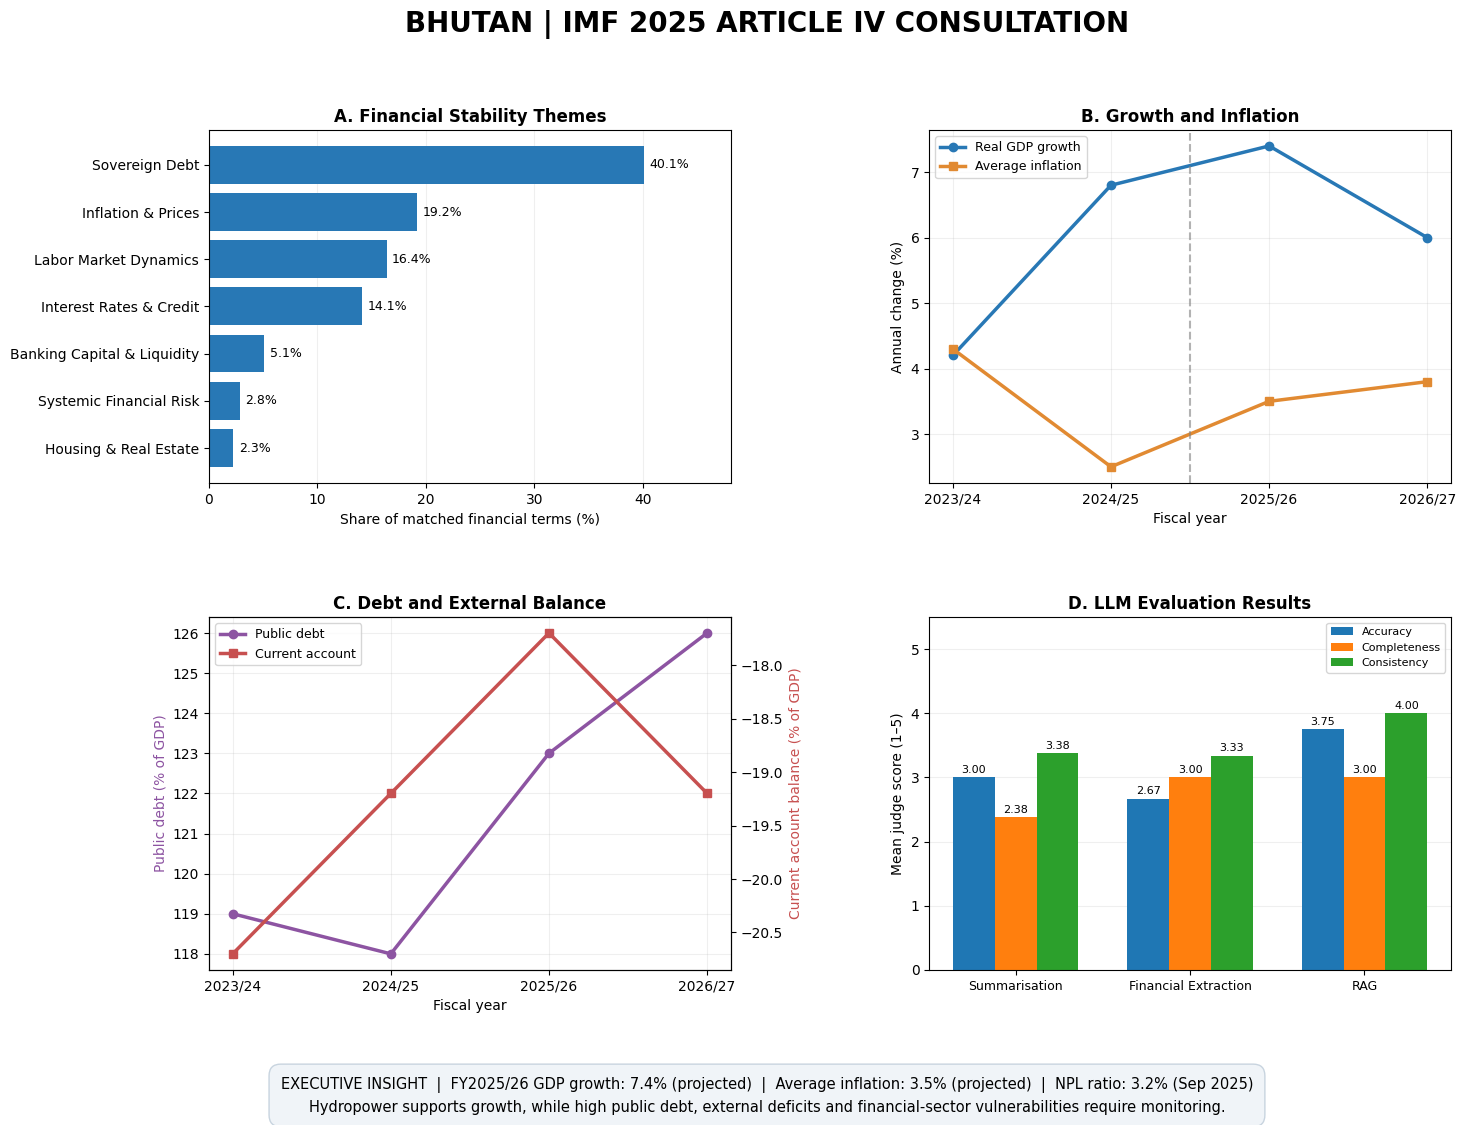

In [21]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Load previously saved project results.
themes_df = pd.read_csv(project_dir / "bhutan_financial_themes.csv")
trends_df = pd.read_csv(project_dir / "bhutan_trends_wide.csv")
scores_df = pd.read_csv(project_dir / "bhutan_llm_evaluations.csv")

# Required tidy transformation.
trends_long = pd.melt(
    trends_df,
    id_vars="indicator",
    var_name="year",
    value_name="value"
)

years = ["2023/24", "2024/25", "2025/26", "2026/27"]

def series(name):
    return (
        trends_long[trends_long["indicator"] == name]
        .set_index("year")
        .reindex(years)["value"]
        .astype(float)
        .to_numpy()
    )

score_summary = (
    scores_df.groupby("category")[
        ["accuracy", "completeness", "consistency"]
    ].mean()
)

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.patch.set_facecolor("white")

# Panel 1: Seven financial themes
ax = axes[0, 0]
theme_plot = themes_df.sort_values("percentage")

bars = ax.barh(
    theme_plot["theme"],
    theme_plot["percentage"],
    color="#2878B5"
)

ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=9)
ax.set_xlim(0, max(theme_plot["percentage"]) * 1.2)
ax.set_xlabel("Share of matched financial terms (%)")
ax.set_title("A. Financial Stability Themes", fontweight="bold")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

# Panel 2: Real GDP and inflation
ax = axes[0, 1]

ax.plot(
    years, series("Real GDP growth"),
    marker="o", linewidth=2.5,
    label="Real GDP growth", color="#2878B5"
)
ax.plot(
    years, series("Average inflation"),
    marker="s", linewidth=2.5,
    label="Average inflation", color="#E18A32"
)

ax.axvline(1.5, linestyle="--", color="gray", alpha=0.6)
ax.set_ylabel("Annual change (%)")
ax.set_xlabel("Fiscal year")
ax.set_title("B. Growth and Inflation", fontweight="bold")
ax.legend(fontsize=9)
ax.grid(alpha=0.2)

# Panel 3: Public debt and current account
ax = axes[1, 0]
ax2 = ax.twinx()

line1 = ax.plot(
    years, series("Public debt"),
    marker="o", linewidth=2.5,
    color="#8D54A2", label="Public debt"
)
line2 = ax2.plot(
    years, series("Current account balance"),
    marker="s", linewidth=2.5,
    color="#C75050", label="Current account"
)

ax.set_ylabel("Public debt (% of GDP)", color="#8D54A2")
ax2.set_ylabel("Current account balance (% of GDP)", color="#C75050")
ax.set_xlabel("Fiscal year")
ax.set_title("C. Debt and External Balance", fontweight="bold")
ax.grid(alpha=0.2)

lines = line1 + line2
ax.legend(
    lines, [line.get_label() for line in lines],
    loc="upper left", fontsize=9
)

# Panel 4: Independent LLM judge scores
ax = axes[1, 1]

metrics = ["accuracy", "completeness", "consistency"]
labels = ["Accuracy", "Completeness", "Consistency"]
categories = [
    c for c in ["Summarisation", "Financial Extraction", "RAG"]
    if c in score_summary.index
]

x = np.arange(len(categories))
width = 0.24

for i, metric in enumerate(metrics):
    values = score_summary.loc[categories, metric].to_numpy()
    bars = ax.bar(
        x + (i - 1) * width,
        values, width, label=labels[i]
    )
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=9)
ax.set_ylim(0, 5.5)
ax.set_ylabel("Mean judge score (1–5)")
ax.set_title("D. LLM Evaluation Results", fontweight="bold")
ax.legend(fontsize=8, loc="upper right")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

# Executive title and insight overlay
fig.suptitle(
    "BHUTAN | IMF 2025 ARTICLE IV CONSULTATION",
    fontsize=20, fontweight="bold", y=0.98
)


insight = (
    "EXECUTIVE INSIGHT  |  FY2025/26 GDP growth: 7.4% (projected)  |  "
    "Average inflation: 3.5% (projected)  |  "
    "NPL ratio: 3.2% (Sep 2025)\n"
    "Hydropower supports growth, while high public debt, external deficits "
    "and financial-sector vulnerabilities require monitoring."
)

fig.text(
    0.5, 0.075, insight,
    ha="center", va="center",
    fontsize=10.5, linespacing=1.6,
    bbox=dict(
        boxstyle="round,pad=0.8",
        facecolor="#F0F4F8",
        edgecolor="#C8D4DF"
    )
)


fig.subplots_adjust(
    left=0.19, right=0.88,
    top=0.88, bottom=0.18,
    hspace=0.38, wspace=0.38
)

output_path = project_dir / "bhutan_imf_dashboard.png"
fig.savefig(
    output_path,
    dpi=350,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

